# Supplementary Figure S3b. AUPRC of TransMap-global versus ARCHIE across per-SNP trans heritability and sparsity

Mean area under the precision-recall curve (AUPRC) for recovering true variant-gene pairs, TransMap-global (y) versus ARCHIE (x), averaged over 1,000 simulation replicates per setting. Colours are per-SNP trans heritability (0.0025, 0.004, 0.01); shapes are the sparsity parameter (sumabs fixed at 0.4-0.8, or chosen by cross-validation, CV). The dashed line is y = x. Standard errors of the mean AUPRC (≤ 0.0018) are kept in the rds but not drawn.

Input: `data/Figure_S3b_auprc_sparsity.rds`.

In [1]:
library(ggplot2)
a <- readRDS("data/Figure_S3b_auprc_sparsity.rds")
a

per_snp_h2,sparsity,n_rep,auprc_archie,auprc_transmap_global,se_archie,se_transmap_global
<dbl>,<chr>,<int>,<dbl>,<dbl>,<dbl>,<dbl>
0.0025,0.4,1000,0.4892997,0.5927491,0.001817052,0.0017500963
0.0025,0.5,1000,0.5183292,0.6395179,0.001755025,0.0017924276
0.0025,0.6,1000,0.5116986,0.6321966,0.001547374,0.0016919833
0.0025,0.7,1000,0.5010198,0.6055539,0.001386938,0.0015256061
0.0025,0.8,1000,0.4974170,0.5959835,0.001339723,0.0014235749
0.0025,CV,1000,0.4971687,0.5964244,0.001376666,0.0014475199
0.0040,0.4,1000,0.5596883,0.6810289,0.001737776,0.0014585978
0.0040,0.5,1000,0.5968658,0.7425327,0.001749568,0.0016047555
0.0040,0.6,1000,0.5877786,0.7396898,0.001623464,0.0016022228


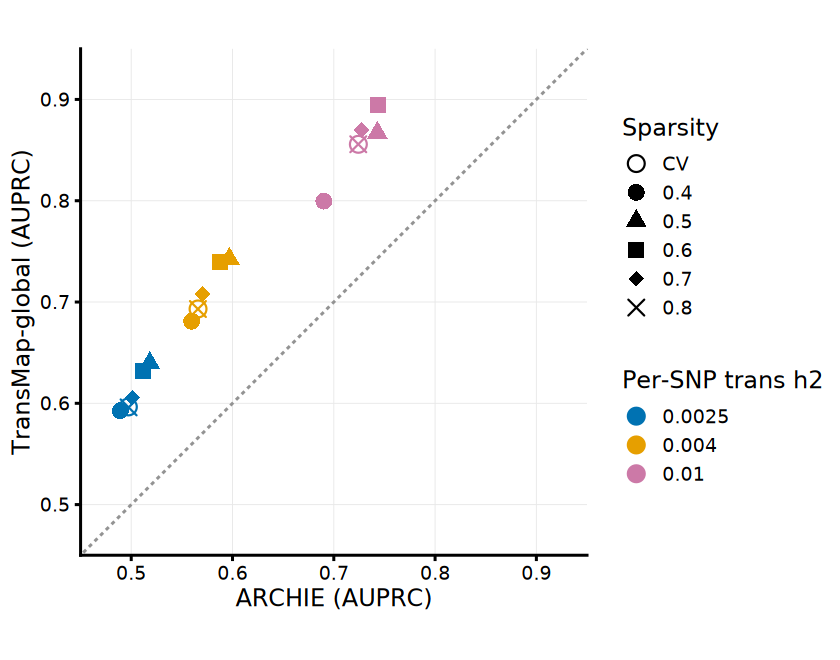

In [2]:
a$h2_label <- factor(a$per_snp_h2, levels = c(0.0025, 0.004, 0.01), labels = c("0.0025", "0.004", "0.01"))
a$sparsity <- factor(a$sparsity, levels = c("CV", "0.4", "0.5", "0.6", "0.7", "0.8"))
h2_colors <- c("0.0025" = "#0072B2", "0.004" = "#E69F00", "0.01" = "#CC79A7")
shapes <- c("CV" = 1, "0.4" = 16, "0.5" = 17, "0.6" = 15, "0.7" = 18, "0.8" = 4)

p <- ggplot(a, aes(x = auprc_archie, y = auprc_transmap_global, colour = h2_label, shape = sparsity)) +
  geom_abline(slope = 1, intercept = 0, linetype = "dashed", colour = "#939393") +
  geom_point(size = 4, stroke = 0.7) +
  scale_colour_manual(values = h2_colors, name = "Per-SNP trans h2") +
  scale_shape_manual(values = shapes, name = "Sparsity") +
  coord_fixed(xlim = c(0.45, 0.95), ylim = c(0.45, 0.95), expand = FALSE) +
  labs(x = "ARCHIE (AUPRC)", y = "TransMap-global (AUPRC)") +
  theme_classic(base_size = 14) +
  theme(panel.grid.major = element_line(linewidth = 0.2, colour = "#E8E8E8"))

options(repr.plot.width = 7, repr.plot.height = 5.5)
p